# Case Study 4: Pricing, Hedging, and Calibrating a Real Option

## Setup

`DATA_DIR` is the folder holding the daily `opra-pillar-YYYYMMDD.cbbo-1m.csv.zst` files. Every derived cache is written to `DATA_DIR/cache`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm
from scipy.optimize import brentq

warnings.filterwarnings("ignore", message=".*inplace keyword.*")  # yfinance/pandas 3 deprecation chatter

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(exist_ok=True)
SEED = 5005

## Section 0 — Model Functions from Modules 10–11

These are the Module 11 `black_scholes`, `greeks` and `implied_vol`, reused as written. Module 11's `simulate_hedge_pnl` is extended in Section 4.

In [2]:
def bs_d1_d2(S, K, r, sigma, tau):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return d1, d1 - sigma * np.sqrt(tau)

def greeks(S, K, r, sigma, tau, option="call"):
    d1, d2 = bs_d1_d2(S, K, r, sigma, tau)
    gamma = norm.pdf(d1) / (S * sigma * np.sqrt(tau))
    vega = S * norm.pdf(d1) * np.sqrt(tau)
    if option == "call":
        delta = norm.cdf(d1)
        theta = -S * norm.pdf(d1) * sigma / (2 * np.sqrt(tau)) - r * K * np.exp(-r * tau) * norm.cdf(d2)
    else:
        delta = norm.cdf(d1) - 1
        theta = -S * norm.pdf(d1) * sigma / (2 * np.sqrt(tau)) + r * K * np.exp(-r * tau) * norm.cdf(-d2)
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta}

def black_scholes(S, K, r, sigma, tau, option="call"):
    d1, d2 = bs_d1_d2(S, K, r, sigma, tau)
    if option == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)
    return K * np.exp(-r * tau) * norm.cdf(-d2) - S * norm.cdf(-d1)

def implied_vol(price, S, K, r, tau, option="call"):
    objective = lambda sigma: black_scholes(S, K, r, sigma, tau, option) - price
    return brentq(objective, 1e-4, 5.0)

## Section 1 — Data Pipeline

### 1.1 — Getting the Data

The data is a Databento pull of OPRA.PILLAR, schema `cbbo-1m`, parent symbol `SPX.OPT`, from 2026-08-03 through 2026-10-30, as one zstd-compressed CSV per trading day. Raw files and caches stay in `data/`, which `.gitignore` excludes.

In [3]:
raw_files = sorted(DATA_DIR.glob("opra-pillar-*.cbbo-1m.csv.zst"))
file_dates = pd.to_datetime([f.name.split("-")[2].split(".")[0] for f in raw_files])
print(f"daily files: {len(raw_files)}")
print(f"first day:   {file_dates[0].date()}")
print(f"last day:    {file_dates[-1].date()}")

daily files: 64
first day:   2026-08-03
last day:    2026-10-30


### 1.2 — Choosing a Working Universe

Only the `symbol` column of the first and last day's files is read, to see which expirations exist at each end of the window.

In [4]:
def expirations_in(path):
    sym = pd.read_csv(path, compression="zstd", usecols=["symbol"])["symbol"]
    return set(pd.to_datetime(sym.str[6:12].unique(), format="%y%m%d"))

exp_first, exp_last = expirations_in(raw_files[0]), expirations_in(raw_files[-1])
exp_table = pd.DataFrame(index=sorted(exp_first | exp_last))
exp_table.index.name = "expiration"
exp_table["on_first_day"] = exp_table.index.isin(exp_first)
exp_table["on_last_day"] = exp_table.index.isin(exp_last)
exp_table["days_to_exp_from_last_day"] = (exp_table.index - file_dates[-1]).days
print(exp_table.to_string())

            on_first_day  on_last_day  days_to_exp_from_last_day
expiration                                                      
2026-08-21          True        False                        -70
2026-09-18          True        False                        -42
2026-10-16          True        False                        -14
2026-11-20          True         True                         21
2026-12-18          True         True                         49
2027-01-15          True         True                         77
2027-02-19          True         True                        112
2027-03-19          True         True                        140
2027-04-16          True         True                        168
2027-05-21          True         True                        203
2027-06-17          True         True                        230
2027-07-16          True         True                        259
2027-08-20          True         True                        294
2027-09-17          True 

August 21, September 18 and October 16 are listed on the first day and gone by the last. I use the October 16, 2026 monthly as the near expiration because it is observed longest (about ten weeks), which gives Section 4.2 the most rebalances. The far expiration is the June 2027 monthly, which expires Thursday, June 17 because Friday, June 18 is the Juneteenth holiday. It is about 7.5 months out on the last day and present every day (checked in the Section 1.4 panel). October has expired by "today" (October 30), so Sections 2, 3 and 6 use the November 20, 2026 monthly, the nearest expiration still trading. Strikes are limited to ±15% of each day's SPX close.

In [5]:
NEAR_EXP = pd.Timestamp("2026-10-16")    # full lifecycle inside the window (Section 4.2)
TODAY_NEAR_EXP = pd.Timestamp("2026-11-20")  # nearest expiration on today's chain (Sections 2, 3, 6)
FAR_EXP = pd.Timestamp("2027-06-17")     # further-dated (Sections 3, 4.1, 5, 7)
MONEYNESS_BAND = 0.15
UNIVERSE = [NEAR_EXP, TODAY_NEAR_EXP, FAR_EXP]
assert all(e in exp_first for e in UNIVERSE) and NEAR_EXP not in exp_last
assert TODAY_NEAR_EXP in exp_last and FAR_EXP in exp_last

In [6]:
# AM-settlement check: raw one-minute rows for the near expiration on the days up to its nominal expiration
near_code = NEAR_EXP.strftime("%y%m%d")
check = (file_dates >= NEAR_EXP - pd.Timedelta(days=3)) & (file_dates <= NEAR_EXP)
for path, date in zip(np.array(raw_files)[check], file_dates[check]):
    sym = pd.read_csv(path, compression="zstd", usecols=["symbol"])["symbol"]
    near = sym[sym.str[6:12] == near_code]
    print(f"{date.date()} ({date:%a}): raw rows {len(near):>7,}   contracts {near.nunique():>4}")

2026-10-13 (Tue): raw rows 372,838   contracts 1090
2026-10-14 (Wed): raw rows 453,358   contracts 1090
2026-10-15 (Thu): raw rows 445,881   contracts 1090
2026-10-16 (Fri): raw rows       0   contracts    0


On October 13 through 15 the October 16 expiration has 1,090 contracts and 370,000 to 450,000 one-minute rows a day. On Friday, October 16 it has none, so the last live quotes come the trading day before expiration, as expected for AM-settled SPX monthlies.

### 1.3 — The Underlying and the Risk-Free Rate

I use `^SPX`. `^GSPC` is the same S&P 500 index under Yahoo's other ticker, so the only thing that could differ is how each feed records the close, and the cell below checks that the closes match exactly. SPY closes are unadjusted, since the dividend is credited to cash separately in Section 4 and adjusted prices would double count it. `^IRX` is the 13-week T-bill yield in percent, converted with $r = \ln(1 + \text{IRX}/100)$. SPY's dividend yield $q$ is trailing twelve-month dividends over its close. History starts 2026-01-02, which gives 145 trading days before the window for realized volatility.

In [7]:
mkt_path, div_path = CACHE_DIR / "market.pkl", CACHE_DIR / "spy_dividends.pkl"
if mkt_path.exists() and div_path.exists():
    mkt, spy_divs = pd.read_pickle(mkt_path), pd.read_pickle(div_path)
else:
    raw_mkt = yf.download(["^SPX", "^GSPC", "SPY", "^IRX"], start="2026-01-01", end="2026-11-03",
                          auto_adjust=False, progress=False)["Close"]
    mkt = raw_mkt.rename(columns={"^SPX": "spx", "^GSPC": "gspc", "SPY": "spy", "^IRX": "irx"})
    spy_divs = yf.Ticker("SPY").dividends
    spy_divs.index = spy_divs.index.tz_localize(None).normalize()
    mkt.to_pickle(mkt_path)
    spy_divs.to_pickle(div_path)

mkt = mkt.loc[:file_dates[-1]].dropna()
mkt["r"] = np.log(1 + mkt["irx"] / 100)

def trailing_q(date):
    # SPY dividend yield: dividends with ex-date in the trailing 12 months / SPY close on `date`
    paid = spy_divs.loc[date - pd.DateOffset(years=1) + pd.Timedelta(days=1): date].sum()
    return paid / mkt.loc[date, "spy"]

TODAY = file_dates[-1]
print(f"history: {mkt.index[0].date()} to {mkt.index[-1].date()}")
print(f"trading days before OPRA window: {(mkt.index < file_dates[0]).sum()}")
print(f"OPRA dates missing from yfinance: {len(file_dates.difference(mkt.index))}")
print(f"max |^SPX - ^GSPC| close: {(mkt['spx'] - mkt['gspc']).abs().max():.4f}")
print(f"SPX close today ({TODAY.date()}): {mkt.loc[TODAY, 'spx']:.2f}")
print(f"SPY close today: {mkt.loc[TODAY, 'spy']:.2f}")
print(f"r today (continuous): {mkt.loc[TODAY, 'r']:.4%}")
print(f"SPY trailing dividend yield q, today: {trailing_q(TODAY):.4%}")
print(f"SPY trailing dividend yield q, {file_dates[0].date()}: {trailing_q(file_dates[0]):.4%}")

history: 2026-01-02 to 2026-10-30
trading days before OPRA window: 145
OPRA dates missing from yfinance: 0
max |^SPX - ^GSPC| close: 0.0000
SPX close today (2026-10-30): 7580.07
SPY close today: 755.72
r today (continuous): 3.8961%
SPY trailing dividend yield q, today: 1.0034%
SPY trailing dividend yield q, 2026-08-03: 0.9932%


### 1.4 — Building the Panel

Each day's file is read compressed with only the six needed columns, cut to the three expirations with a string slice of `symbol`, and limited to ±15% of that day's SPX close before timestamps are parsed.

I keep one snapshot per contract, the row closest to 15:59 ET. That is the last full minute before the 16:00 close, so it matches the closing level used as $S$ without using the closing-print minute. A contract with no row within 15 minutes of 15:59 is left out that day rather than given a stale quote. The mid is $(\text{bid} + \text{ask})/2$. Time to maturity is $\tau = (\text{expiration} - \text{date})/365$ in calendar days, with "today" as day 0, everywhere below. Realized volatility is annualized with $\sqrt{252}$ because 252 trading-day returns span one calendar year.

In [8]:
SNAP_TIME_ET = "15:59"
RAW_COLS = ["ts_recv", "bid_px_00", "ask_px_00", "bid_sz_00", "ask_sz_00", "symbol"]
EXP_CODES = {e.strftime("%y%m%d") for e in UNIVERSE}
PANEL_COLS = ["date", "symbol", "expiration", "type", "strike", "tau",
              "bid", "ask", "mid", "bid_size", "ask_size"]

def process_day(path, date, spot, exp_codes=EXP_CODES, band=MONEYNESS_BAND):
    raw = pd.read_csv(path, compression="zstd", usecols=RAW_COLS)
    exp_code = raw["symbol"].str[6:12]
    df = raw.loc[exp_code.isin(exp_codes)].copy()              # 1) expiration filter first
    df["strike"] = df["symbol"].str[13:21].astype(int) / 1000
    df = df.loc[(df["strike"] / spot - 1).abs() <= band]  # 2) moneyness band
    target = pd.Timestamp(f"{date.date()} {SNAP_TIME_ET}", tz="America/New_York").tz_convert("UTC")
    gap = (pd.to_datetime(df["ts_recv"], utc=True) - target).abs()
    df = df.assign(gap=gap).sort_values("gap").drop_duplicates("symbol")  # 3) one snapshot per contract
    df = df.loc[df["gap"] <= pd.Timedelta("15min")]
    out = pd.DataFrame({
        "date": date,
        "symbol": df["symbol"],
        "expiration": pd.to_datetime(df["symbol"].str[6:12], format="%y%m%d"),
        "type": np.where(df["symbol"].str[12] == "C", "call", "put"),
        "strike": df["strike"],
        "bid": df["bid_px_00"], "ask": df["ask_px_00"],
        "bid_size": df["bid_sz_00"], "ask_size": df["ask_sz_00"],
    })
    out["tau"] = (out["expiration"] - date).dt.days / 365
    out["mid"] = (out["bid"] + out["ask"]) / 2
    return out[PANEL_COLS].sort_values(["expiration", "type", "strike"])

def load_day(path, date):
    tag = "_".join(sorted(EXP_CODES)) + f"_m{int(MONEYNESS_BAND * 100)}_{SNAP_TIME_ET.replace(':', '')}"
    cache = CACHE_DIR / f"day_{date:%Y%m%d}_{tag}.pkl"
    if cache.exists():
        return pd.read_pickle(cache)
    result = process_day(path, date, mkt.loc[date, "spx"])
    pd.to_pickle(result, cache)
    return result

days = [load_day(p, d) for p, d in zip(raw_files, file_dates)]
panel = pd.concat(days, ignore_index=True)

print(f"panel rows: {len(panel):,}  (one per contract per day)")
print(f"duplicate (symbol, date) rows: {panel.duplicated(['symbol', 'date']).sum()}")
print(f"days in panel: {panel['date'].nunique()}")
print(panel.groupby("expiration").agg(contracts_in_band=("symbol", "nunique"), days_present=("date", "nunique"),
                                     first_day=("date", "min"), last_day=("date", "max")).to_string())
panel.head()

panel rows: 84,248  (one per contract per day)
duplicate (symbol, date) rows: 0
days in panel: 64
            contracts_in_band  days_present  first_day   last_day
expiration                                                       
2026-10-16                774            53 2026-08-03 2026-10-15
2026-11-20                742            64 2026-08-03 2026-10-30
2027-06-17                198            64 2026-08-03 2026-10-30


,date,symbol,expiration,type,strike,tau,bid,ask,mid,bid_size,ask_size
0,2026-08-03,SPX 261016C06470000,2026-10-16,call,6470.0,0.20274,1196.2,1198.8,1197.50,3,3
1,2026-08-03,SPX 261016C06475000,2026-10-16,call,6475.0,0.20274,1191.4,1194.0,1192.70,3,3
2,2026-08-03,SPX 261016C06480000,2026-10-16,call,6480.0,0.20274,1186.6,1189.2,1187.90,3,3
3,2026-08-03,SPX 261016C06490000,2026-10-16,call,6490.0,0.20274,1177.1,1179.6,1178.35,3,3
4,2026-08-03,SPX 261016C06500000,2026-10-16,call,6500.0,0.20274,1167.7,1169.8,1168.75,3,3


Caching is per day. Each raw file is about 60 MB compressed and 4 million rows, so a full rebuild of 64 days takes minutes. The reduced result (about 1,300 rows, one snapshot per contract) is pickled under a name encoding the expirations, moneyness band and snapshot time, so a rerun takes under a second and changing the universe triggers a rebuild rather than reusing stale data. I used pickle instead of Parquet only because the quant-ts environment has no Parquet engine.

## Section 2 — From Model to Market: Pricing and No-Arbitrage Checks

"Today" is 2026-10-30 and the nearer expiration is November 20, 2026 ($\tau = 21/365$). Market price means the bid-ask mid unless bid or ask is named. The single $\sigma$ is the realized volatility of SPX daily log returns over the trailing 63 trading days, annualized with $\sqrt{252}$. Section 3 reuses it.

In [9]:
S0, r0 = mkt.loc[TODAY, "spx"], mkt.loc[TODAY, "r"]
log_ret = np.log(mkt["spx"]).diff().dropna()
RV_WINDOW = 63
sigma_rv = log_ret.loc[:TODAY].tail(RV_WINDOW).std() * np.sqrt(252)

today_chain = panel[panel["date"] == TODAY]
near_today = today_chain[today_chain["expiration"] == TODAY_NEAR_EXP]
tau_near = near_today["tau"].iloc[0]
print(f"S (SPX close): {S0:.2f}")
print(f"r: {r0:.4%}")
print(f"tau (Nov 20 expiry): {tau_near:.5f} years ({tau_near * 365:.0f} calendar days)")
print(f"63-day realized vol: {sigma_rv:.4%}")

S (SPX close): 7580.07
r: 3.8961%
tau (Nov 20 expiry): 0.05753 years (21 calendar days)
63-day realized vol: 10.5398%


### 2.1 — Black-Scholes Price vs. Market Quote

Five calls are priced at the strikes nearest 95%, 97.5%, 100%, 102.5% and 105% of spot. The last column is the gap between model and mid in half-spreads, so an absolute value of 1 or less means the model price is inside the spread.

In [10]:
calls_near = near_today[near_today["type"] == "call"].set_index("strike")
rows = []
for m in [0.95, 0.975, 1.00, 1.025, 1.05]:
    K = calls_near.index[np.abs(calls_near.index - m * S0).argmin()]
    q = calls_near.loc[K]
    bs = black_scholes(S0, K, r0, sigma_rv, tau_near, "call")
    rows.append({
        "strike": K, "K/S": K / S0,
        "moneyness": "ATM" if abs(K / S0 - 1) <= 0.005 else ("ITM" if K < S0 else "OTM"),
        "bid": q["bid"], "ask": q["ask"], "mid": q["mid"], "BS (RV sigma)": bs,
        "BS - mid": bs - q["mid"],
        "position": "below bid" if bs < q["bid"] else ("above ask" if bs > q["ask"] else "inside spread"),
        "(BS - mid) / half-spread": (bs - q["mid"]) / ((q["ask"] - q["bid"]) / 2),
    })
bs_vs_mkt = pd.DataFrame(rows).set_index("strike")
bs_vs_mkt.round(3)

,K/S,moneyness,bid,ask,mid,BS (RV sigma),BS - mid,position,(BS - mid) / half-spread
strike,,,,,,,,,
7200.0,0.950,ITM,420.2,428.3,424.25,397.322,-26.928,below bid,-6.649
7390.0,0.975,ITM,257.7,264.7,261.20,219.762,-41.438,below bid,-11.839
7580.0,1.000,ATM,123.1,124.5,123.80,85.186,-38.614,below bid,-55.163
7770.0,1.025,OTM,33.9,35.1,34.50,19.814,-14.686,below bid,-24.477
7960.0,1.050,OTM,4.9,5.5,5.20,2.493,-2.707,below bid,-9.024


With $\sigma$ = 10.54%, the Black-Scholes price is below the bid at all five strikes, so none lands inside the spread. Prices are in index points (an SPX contract is \$100 per point). The misses are biggest near the money (41.44 points under the mid at 7390, 38.61 at 7580). The wings are closer in dollars because the 7200 call is mostly intrinsic value and the 7960 call is worth only a few dollars. Even the tight at-the-money quote is missed by 55 half-spreads, so the spread can't explain it.

The market is using a higher volatility than SPX has realized. Option prices look forward, and the next three weeks include the November 3 midterm election and data releases. Sellers also can't fully hedge volatility or jump risk, so they charge for it.

### 2.2 — Put-Call Parity, Properly Bounded

For every strike within ±2% of spot on the November 20 expiration with both quotes, I check whether either side of parity makes money after crossing both spreads. Selling the call at its bid, buying the put at its ask, buying $S$ and borrowing $Ke^{-r\tau}$ locks in $(C_{bid} - P_{ask}) - (S - Ke^{-r\tau})$. The reverse (buy the call at its ask, sell the put at its bid, short $S$, lend $Ke^{-r\tau}$) locks in $(S - Ke^{-r\tau}) - (C_{ask} - P_{bid})$. A positive value in either column would be an arbitrage.

In [11]:
quotes = near_today.pivot_table(index="strike", columns="type", values=["bid", "ask", "mid"]).dropna()
atm = quotes[np.abs(quotes.index / S0 - 1) <= 0.02]
K = atm.index.to_numpy()
fwd = S0 - K * np.exp(-r0 * tau_near)                      # S - K e^{-r tau}
parity = pd.DataFrame({
    "C bid": atm[("bid", "call")], "C ask": atm[("ask", "call")],
    "P bid": atm[("bid", "put")], "P ask": atm[("ask", "put")],
    "S - Ke^(-rt)": fwd,
    "mid gap": atm[("mid", "call")] - atm[("mid", "put")] - fwd,
    "sell C / buy P profit": atm[("bid", "call")] - atm[("ask", "put")] - fwd,
    "buy C / sell P profit": fwd - (atm[("ask", "call")] - atm[("bid", "put")]),
}, index=atm.index)

print(f"strikes checked: {len(parity)}")
print(f"mid gap: mean {parity['mid gap'].mean():.3f}, min {parity['mid gap'].min():.3f}, max {parity['mid gap'].max():.3f}")
print(f"combined spread (call + put), median: {((atm[('ask', 'call')] - atm[('bid', 'call')]) + (atm[('ask', 'put')] - atm[('bid', 'put')])).median():.2f}")
for col in ["sell C / buy P profit", "buy C / sell P profit"]:
    print(f"{col}: max {parity[col].max():.3f}, strikes with profit > 0: {(parity[col] > 0).sum()}")
q_spy = trailing_q(TODAY)
div_term = S0 * (1 - np.exp(-q_spy * tau_near))
print(f"dividend term omitted by the formula, S(1 - e^(-q tau)) with SPY q = {q_spy:.4%}: {div_term:.3f}")
print(f"buy C / sell P profit net of dividend term: max {(parity['buy C / sell P profit'] - div_term).max():.3f}, "
      f"strikes with profit > 0: {(parity['buy C / sell P profit'] - div_term > 0).sum()}")
parity.iloc[::max(1, len(parity) // 8)].round(3)

strikes checked: 61
mid gap: mean -4.968, min -5.406, max -4.511
combined spread (call + put), median: 4.30
sell C / buy P profit: max -6.275, strikes with profit > 0: 0
buy C / sell P profit: max 3.829, strikes with profit > 0: 61
dividend term omitted by the formula, S(1 - e^(-q tau)) with SPY q = 1.0034%: 4.375
buy C / sell P profit net of dividend term: max -0.545, strikes with profit > 0: 0


,C bid,C ask,P bid,P ask,S - Ke^(-rt),mid gap,sell C / buy P profit,buy C / sell P profit
strike,,,,,,,,
7430.0,226.0,232.4,67.4,68.4,166.706,-5.406,-9.106,1.706
7465.0,202.1,203.7,75.7,76.9,131.785,-5.185,-6.585,3.785
7500.0,176.7,178.0,84.9,86.2,96.863,-5.063,-6.363,3.763
7535.0,152.3,153.8,94.6,97.4,61.941,-4.891,-7.041,2.741
7570.0,129.4,130.8,106.6,109.5,27.020,-4.970,-7.120,2.820
7605.0,108.1,109.5,120.1,123.1,-7.902,-4.898,-7.098,2.698
7640.0,88.4,89.8,135.3,138.4,-42.824,-4.926,-7.176,2.676
7675.0,70.8,72.1,152.5,155.5,-77.745,-4.805,-6.955,2.655
7710.0,55.2,56.5,169.7,177.6,-112.667,-5.133,-9.733,0.533


With the formula as given, the mid gap is between −4.51 and −5.41 at all 61 strikes, so calls look cheap relative to puts. Selling the call and buying the put never pays after the spreads, but the reverse trade shows a profit at every strike, up to 3.83 points. I don't think that is real, because the formula assumes no dividends and someone short the index owes them. The correct version is $C - P = Se^{-q\tau} - Ke^{-r\tau}$. With SPY's 1.00% trailing yield as a proxy, the dividend term is worth 4.38 points, most of the gap. After subtracting it the best trade loses 0.55 points and no strike is profitable. What is left (about 0.59 points at the mid) is well inside the 4.30-point median combined spread. Most of it is probably the index yielding more than SPY: SPY's dividends are paid net of its 0.0945% expense ratio, which is worth about 0.41 points here. The rest could come from matching 15:59 quotes to the 16:00 close.

This fits Module 9. Under the risk-neutral measure discounted prices are martingales, so a long call plus a short put, which pays $S_T - K$ in every state, must cost its discounted expected payoff: $S - Ke^{-r\tau}$ without dividends and $Se^{-q\tau} - Ke^{-r\tau}$ with them.

## Section 3 — Implied Volatility and the Smile

Implied vol is backed out of every quote on today's November 20, 2026 and June 17, 2027 chains (calls and puts) from the bid-ask mid, using the Module 11 `implied_vol`. Before solving I drop quotes with no bid (missing or zero), crossed or locked quotes, quotes whose spread is wider than the mid (deep out-of-the-money options at the 0.05 minimum bid, where the mid is mostly tick size), and quotes at or below discounted intrinsic value. Anything `brentq` can't bracket on $[10^{-4}, 5]$ is dropped as a solver failure. The smile uses out-of-the-money options only (puts for $K < S$, calls for $K \ge S$). ATM implied vol averages the call and put IVs at the strike nearest spot, which cancels most of the bias from ignoring the index dividend.

In [12]:
def iv_or_reason(mid, bid, ask, S, K, r, tau, option):
    if not bid > 0:                       # missing (NaN) or zero bid
        return np.nan, "no bid"
    if ask <= bid:
        return np.nan, "crossed/locked"
    if ask - bid > mid:                   # spread wider than the price itself: mid is mostly tick noise
        return np.nan, "spread > mid"
    intrinsic = max(S - K * np.exp(-r * tau), 0) if option == "call" else max(K * np.exp(-r * tau) - S, 0)
    if mid <= intrinsic:
        return np.nan, "mid <= intrinsic"
    try:
        return implied_vol(mid, S, K, r, tau, option), "ok"
    except ValueError:
        return np.nan, "solver failed"

smile_chain = today_chain[today_chain["expiration"].isin([TODAY_NEAR_EXP, FAR_EXP])].copy()
solved = [iv_or_reason(q.mid, q.bid, q.ask, S0, q.strike, r0, q.tau, q.type) for q in smile_chain.itertuples()]
smile_chain["iv"] = [v for v, _ in solved]
smile_chain["status"] = [s for _, s in solved]
smile_chain["moneyness"] = smile_chain["strike"] / S0
smile_chain["otm"] = np.where(smile_chain["type"] == "put", smile_chain["strike"] < S0, smile_chain["strike"] >= S0)

print("quote status, all quotes:")
print(smile_chain.groupby(["expiration", "type"])["status"].value_counts().unstack(fill_value=0).to_string())
print("\nquote status, out-of-the-money quotes used in the smile:")
print(smile_chain[smile_chain["otm"]].groupby("expiration")["status"].value_counts().unstack(fill_value=0).to_string())

quote status, all quotes:
status           no bid   ok  spread > mid
expiration type                           
2026-11-20 call       1  324            33
           put        0  358             0
2027-06-17 call       0   91             0
           put        0   91             0

quote status, out-of-the-money quotes used in the smile:
status      no bid   ok  spread > mid
expiration                           
2026-11-20       1  324            33
2027-06-17       0   91             0


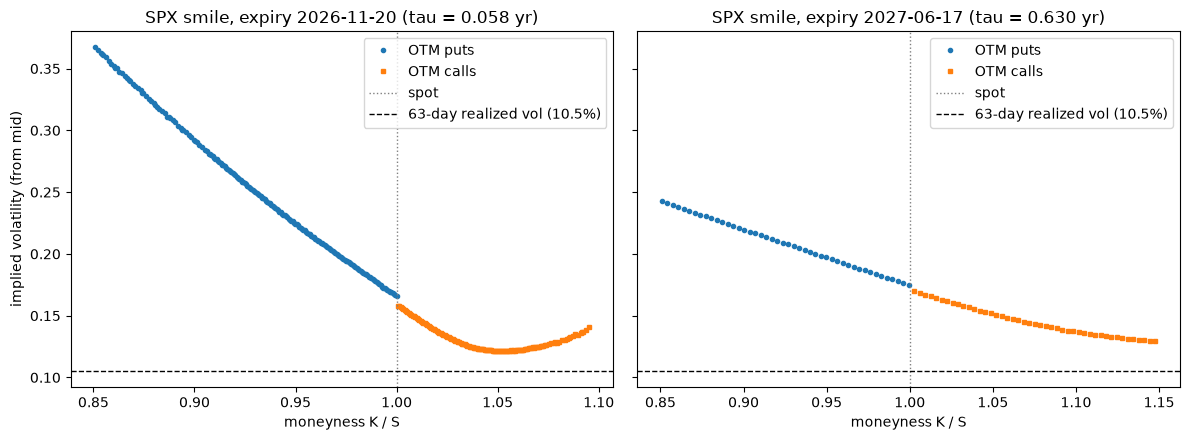

                           2026-11-20  2027-06-17
IV at K/S=0.90                 0.2915      0.2199
IV at K/S=0.95                 0.2244      0.1972
ATM IV                         0.1623      0.1730
IV at K/S=1.05                 0.1213      0.1514
skew: IV(0.95) - IV(1.05)      0.1031      0.0458


In [13]:
def atm_iv(chain_iv, spot):
    # average of call and put IV at the strike nearest spot that has both
    both = chain_iv.dropna(subset=["iv"]).pivot_table(index="strike", columns="type", values="iv").dropna()
    k = both.index[np.abs(both.index - spot).argmin()]
    return both.loc[k].mean(), k

smile = smile_chain[smile_chain["otm"] & (smile_chain["status"] == "ok")].sort_values("strike")
rv21 = log_ret.loc[:TODAY].tail(21).std() * np.sqrt(252)
atm = {e: atm_iv(smile_chain[smile_chain["expiration"] == e], S0) for e in [TODAY_NEAR_EXP, FAR_EXP]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, e in zip(axes, [TODAY_NEAR_EXP, FAR_EXP]):
    s = smile[smile["expiration"] == e]
    for t, mk in [("put", "o"), ("call", "s")]:
        st = s[s["type"] == t]
        ax.plot(st["moneyness"], st["iv"], mk, ms=3, label=f"OTM {t}s")
    ax.axvline(1, color="grey", ls=":", lw=1, label="spot")
    ax.axhline(sigma_rv, color="black", ls="--", lw=1, label=f"63-day realized vol ({sigma_rv:.1%})")
    ax.set_title(f"SPX smile, expiry {e.date()} (tau = {s['tau'].iloc[0]:.3f} yr)")
    ax.set_xlabel("moneyness K / S")
    ax.legend()
axes[0].set_ylabel("implied volatility (from mid)")
plt.tight_layout()
plt.show()

shape = {}
for e in [TODAY_NEAR_EXP, FAR_EXP]:
    s = smile[smile["expiration"] == e]
    iv_at = lambda m: np.interp(m, s["moneyness"], s["iv"])
    shape[e.date()] = {"IV at K/S=0.90": iv_at(0.90), "IV at K/S=0.95": iv_at(0.95), "ATM IV": atm[e][0],
                       "IV at K/S=1.05": iv_at(1.05),
                       "skew: IV(0.95) - IV(1.05)": iv_at(0.95) - iv_at(1.05)}
print(pd.DataFrame(shape).round(4).to_string())

On the November chain, 33 calls were dropped for a spread wider than the mid (calls 10% to 15% out of the money, bid 0.05 to 0.15 against asks of 0.20 to 0.50) and one for having no bid. Nothing was dropped on the June 2027 chain.

Neither expiration is flat. Both show the usual index skew, with out-of-the-money puts at much higher implied vol than calls. November is much steeper: implied vol falls from 29.2% at 90% moneyness to 16.2% at the money, the gap between the 95% and 105% strikes is 10.3 vol points, and it turns back up for calls past about 105%. June 2027 only goes from 22.0% to 17.3%, with a 4.6-point gap between 95% and 105%, so the smile flattens at longer maturity, as it usually does. There is a small jump at spot where the plot switches from puts to calls: within 1% of spot the put IV is about 0.69 vol points above the call IV in November (0.38 in June). It comes from Black-Scholes ignoring the dividend, which pushes put IVs up and call IVs down.

In [14]:
print(f"realized vol, trailing 21 days: {rv21:.4%}")
print(f"realized vol, trailing 63 days: {sigma_rv:.4%}")
for e in [TODAY_NEAR_EXP, FAR_EXP]:
    print(f"ATM IV {e.date()} (strike {atm[e][1]:.0f}): {atm[e][0]:.4%}   ATM IV - 63d RV: {atm[e][0] - sigma_rv:+.4%}")

realized vol, trailing 21 days: 11.8360%
realized vol, trailing 63 days: 10.5398%
ATM IV 2026-11-20 (strike 7580): 16.2292%   ATM IV - 63d RV: +5.6894%
ATM IV 2027-06-17 (strike 7575): 17.3044%   ATM IV - 63d RV: +6.7646%


ATM implied vol is 16.23% for November and 17.30% for June 2027, against 10.54% realized over 63 trading days (11.84% over 21), so implied is 5.7 to 6.8 vol points higher. This is the variance risk premium, which usually runs this way because investors pay for protection against crashes and vol spikes. My data fits that. Trailing realized vol is only a proxy, since the premium is really implied vol against the vol that follows. Section 4.2 gives one forward check: on August 3 the October call implied 14.05% and SPX then delivered 9.78%.

## Section 4 — Delta Hedging: A Simulated Distribution, and One Real Path

Both parts sell one call at its real market mid and delta-hedge it with SPY. P&L is in index points, the same units as the quotes. The true-world $\sigma$ only drives the simulated SPX path in 4.1 and the hedging $\sigma$ only enters $\Delta = N(d_1)$; the code keeps them as separate arguments. $\Delta$ uses the SPX level and $r$ (never $\mu$) and is converted to SPY shares with $h = \Delta \cdot S_{SPX}/S_{SPY}$.

In 4.1 the SPX/SPY ratio is held at today's value on every path, which assumes SPY tracks the index exactly. SPX is simulated as a price index with drift $\mu - q$, where $\mu = 8\%$ is an assumed real-world return (Module 11's value; it never enters a price or $\Delta$). SPY's dividend yield $q$ is credited to cash on the shares held, and cash earns $r$. In 4.2 every input is real: daily SPX and SPY closes, that day's ratio and rate, and SPY's actual dividend on its ex-date.

### 4.1 — A Simulated P&L Distribution

In [15]:
far_chain = today_chain[(today_chain["expiration"] == FAR_EXP) & (today_chain["type"] == "call")].set_index("strike")
FAR_K = far_chain.index[np.abs(far_chain.index - S0).argmin()]
far_q = far_chain.loc[FAR_K]
far_tau, far_mid = far_q["tau"], far_q["mid"]
far_iv = implied_vol(far_mid, S0, FAR_K, r0, far_tau, "call")
spy_ratio0 = S0 / mkt.loc[TODAY, "spy"]
q0 = trailing_q(TODAY)

MU = 0.08
N_PATHS = 20_000
FREQS = {"daily": 1, "weekly": 5, "biweekly": 10, "monthly": 21}   # trading days between rebalances
far_days = round(far_tau * 252)                                       # trading days to expiration

print(f"contract: SPX {FAR_EXP.date()} {FAR_K:.0f} call   ({far_q['symbol']})")
print(f"today's bid / ask / mid: {far_q['bid']:.2f} / {far_q['ask']:.2f} / {far_mid:.2f}")
print(f"tau: {far_tau:.4f} years ({far_days} trading days)")
print(f"true-world sigma (63-day realized vol): {sigma_rv:.4%}")
print(f"contract implied vol (hedging sigma #2): {far_iv:.4%}")
print(f"SPX/SPY ratio held fixed: {spy_ratio0:.4f}   q: {q0:.4%}   r: {r0:.4%}")
far_vega = greeks(S0, FAR_K, r0, far_iv, far_tau)["vega"] / 100
print(f"vega at implied vol: {far_vega:.2f} index points per 1 vol point")

contract: SPX 2027-06-17 7575 call   (SPX   270617C07575000)
today's bid / ask / mid: 505.20 / 508.00 / 506.60
tau: 0.6301 years (159 trading days)
true-world sigma (63-day realized vol): 10.5398%
contract implied vol (hedging sigma #2): 17.1081%
SPX/SPY ratio held fixed: 10.0303   q: 1.0034%   r: 3.8961%
vega at implied vol: 23.25 index points per 1 vol point


In [16]:
def simulate_hedge_pnl(S0, K, r, sigma, T, n_steps, n_paths, mu, rng,
                       premium, sigma_hedge, spy_ratio, q, cost_bps=0.0, option="call"):
    # Module 11's simulator, extended: real premium, separate hedging sigma, SPY hedge with dividends, costs.
    # sigma = true-world vol of the simulated SPX path; sigma_hedge = vol used in the Delta formula.
    dt = T / n_steps
    S = np.full(n_paths, S0)
    cash = np.full(n_paths, premium)
    shares_held = np.zeros(n_paths)                                   # SPY shares

    for i in range(n_steps):
        tau = T - i * dt
        delta = greeks(S, K, r, sigma_hedge, tau, option)["delta"]
        spy = S / spy_ratio
        new_shares = delta * S / spy                                  # h = Delta * S_SPX / S_SPY
        trade = new_shares - shares_held
        cash -= trade * spy + cost_bps / 1e4 * np.abs(trade) * spy    # adjust hedge, pay cost
        shares_held = new_shares
        cash *= np.exp(r * dt)                                        # cash earns the risk-free rate
        cash += shares_held * spy * q * dt                            # SPY dividend on shares held

        Z = rng.normal(size=n_paths)
        S = S * np.exp((mu - q - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

    spy = S / spy_ratio
    cash += shares_held * spy - cost_bps / 1e4 * shares_held * spy    # unwind the hedge
    payoff = np.maximum(S - K, 0) if option == "call" else np.maximum(K - S, 0)
    return cash - payoff

HEDGE_SIGMAS = {"realized": sigma_rv, "implied": far_iv}

def far_hedge(sigma_hedge, freq_days, cost_bps=0.0):
    return simulate_hedge_pnl(S0, FAR_K, r0, sigma_rv, far_tau, max(1, round(far_days / freq_days)), N_PATHS, MU,
                              np.random.default_rng(SEED), premium=far_mid, sigma_hedge=sigma_hedge,
                              spy_ratio=spy_ratio0, q=q0, cost_bps=cost_bps)

far_pnl = {(h, f): far_hedge(s, k) for h, s in HEDGE_SIGMAS.items() for f, k in FREQS.items()}
sim_table = pd.DataFrame({(h, stat): [getattr(far_pnl[(h, f)], stat)() for f in FREQS]
                          for h in HEDGE_SIGMAS for stat in ["mean", "std"]}, index=list(FREQS))
sim_table.columns.names = ["hedging sigma", "terminal P&L"]
sim_table.index.name = "rebalancing"
print(f"BS price at realized vol: {black_scholes(S0, FAR_K, r0, sigma_rv, far_tau):.2f}   "
      f"market mid - BS(realized): {far_mid - black_scholes(S0, FAR_K, r0, sigma_rv, far_tau):.2f}")
sim_table.round(2)

BS price at realized vol: 355.43   market mid - BS(realized): 151.17


hedging sigma realized        implied       
terminal P&L      mean    std    mean    std
rebalancing                                 
daily           188.32  20.57  182.46  46.24
weekly          188.39  38.16  182.49  56.83
biweekly        188.14  51.83  182.48  67.26
monthly         187.21  71.76  181.37  84.03

Both hedges make money on average because the call was sold at 17.11% implied vol and the simulated SPX moves at 10.54%. Black-Scholes at 10.54% values the call at 355.43, 151.17 below the mid. The simulated means come out higher than that because the premium earns interest and the no-dividend formula overvalues a call on a dividend-paying index. Carried to expiration at $r$, the 151.17 gap is worth 154.93, and pricing the call with SPY's 1.00% yield takes another 30.36 (in expiration value) off the realized-vol price. Together that is 185.29, close to the 188.32 daily mean. The hedging $\sigma$ barely moves the mean (188.32 vs. 182.46 at daily rebalancing) but changes the spread a lot. With the realized-vol hedge the std falls from 71.76 monthly to 20.57 daily as discretization error goes away. With the implied-vol hedge it only falls from 84.03 to 46.24, so much of that risk isn't rebalancing error.

### 4.2 — What Actually Happened: One Real Lifecycle

The near contract is the October 16, 2026 call struck closest to SPX's close on its first available day. The hedge opens at the August 3 close and is rebalanced at every close through October 14. On October 15, the last live day, the shares are sold and the call settles at $\max(S_T - K, 0)$ using that day's SPX close, as the prompt specifies (real AM settlement uses the October 16 Special Opening Quotation, built from each component's opening price, which can differ). The hedging $\sigma$'s come from August 3 only: the 63-day realized vol and the contract's own implied vol that day.

In [17]:
near_calls = panel[(panel["expiration"] == NEAR_EXP) & (panel["type"] == "call")]
d0 = near_calls["date"].min()
c0 = near_calls[near_calls["date"] == d0]
NEAR_K = c0["strike"].iloc[np.abs(c0["strike"] - mkt.loc[d0, "spx"]).argmin()]
near_path = near_calls[near_calls["strike"] == NEAR_K].set_index("date").sort_index()
assert (near_path.index == file_dates[(file_dates >= d0) & (file_dates <= near_path.index[-1])]).all()

S_d0, r_d0, tau_d0, mid_d0 = mkt.loc[d0, "spx"], mkt.loc[d0, "r"], near_path["tau"].iloc[0], near_path["mid"].iloc[0]
rv_d0 = log_ret.loc[:d0].tail(RV_WINDOW).std() * np.sqrt(252)
iv_d0 = implied_vol(mid_d0, S_d0, NEAR_K, r_d0, tau_d0, "call")
NEAR_SIGMAS = {"realized": rv_d0, "implied": iv_d0}

def real_hedge_pnl(path, K, sigma_hedge, cost_bps=0.0, option="call"):
    # Daily walk-forward version of simulate_hedge_pnl on real closes; returns P&L and the day-by-day book
    dates = path.index
    spx, spy, r = (mkt.loc[dates, c].to_numpy() for c in ["spx", "spy", "r"])
    cash, shares_held, book = path["mid"].iloc[0], 0.0, []
    for i, d in enumerate(dates):
        if i > 0:
            cash *= np.exp(r[i - 1] * (d - dates[i - 1]).days / 365)
            cash += shares_held * spy_divs[(spy_divs.index > dates[i - 1]) & (spy_divs.index <= d)].sum()
        if i < len(dates) - 1:
            delta = greeks(spx[i], K, r[i], sigma_hedge, path["tau"].iloc[i], option)["delta"]
            new_shares = delta * spx[i] / spy[i]
        else:
            new_shares = 0.0                                          # unwind on the last live day
        trade = new_shares - shares_held
        cash -= trade * spy[i] + cost_bps / 1e4 * abs(trade) * spy[i]
        shares_held = new_shares
        book.append({"date": d, "SPX": spx[i], "SPY": spy[i], "SPY shares": shares_held, "cash": cash})
    payoff = max(spx[-1] - K, 0) if option == "call" else max(K - spx[-1], 0)
    return cash - payoff, pd.DataFrame(book).set_index("date")

real_pnl, books = {}, {}
for h, s in NEAR_SIGMAS.items():
    real_pnl[h], books[h] = real_hedge_pnl(near_path, NEAR_K, s)

realized_over_life = log_ret.loc[d0:near_path.index[-1]].iloc[1:].std() * np.sqrt(252)
print(f"contract: SPX {NEAR_EXP.date()} {NEAR_K:.0f} call   ({near_path['symbol'].iloc[0]})")
print(f"first day {d0.date()}: SPX {S_d0:.2f}, mid {mid_d0:.2f}, tau {tau_d0:.4f}")
print(f"hedging sigma, realized (63d to {d0.date()}): {rv_d0:.4%}   implied (on {d0.date()}): {iv_d0:.4%}")
print(f"last live day {near_path.index[-1].date()}: SPX close {mkt.loc[near_path.index[-1], 'spx']:.2f}, "
      f"payoff {max(mkt.loc[near_path.index[-1], 'spx'] - NEAR_K, 0):.2f}")
print(f"SPX realized vol actually delivered over the hedge: {realized_over_life:.4%}")
for h in NEAR_SIGMAS:
    print(f"real-path hedging P&L, {h} hedging sigma: {real_pnl[h]:.2f}")
books["implied"].iloc[[0, 1, 2, -3, -2, -1]].round(3)

contract: SPX 2026-10-16 7600 call   (SPX   261016C07600000)
first day 2026-08-03: SPX 7600.50, mid 220.50, tau 0.2027
hedging sigma, realized (63d to 2026-08-03): 13.7228%   implied (on 2026-08-03): 14.0475%
last live day 2026-10-15: SPX close 7744.06, payoff 144.06
SPX realized vol actually delivered over the hedge: 9.7807%
real-path hedging P&L, realized hedging sigma: 74.25
real-path hedging P&L, implied hedging sigma: 74.79


,SPX,SPY,SPY shares,cash
date,,,,
2026-08-03,7600.50,757.67,5.610,-4030.239
2026-08-04,7736.52,771.33,6.689,-4862.826
2026-08-05,7723.55,769.79,6.596,-4791.280
2026-10-13,7805.45,778.01,9.865,-7392.024
2026-10-14,7718.94,769.60,9.385,-7023.574
2026-10-15,7744.06,771.79,0.000,218.852


I compare the real path to the simulation two ways. The prompt asks for the percentile in the 4.1 daily distribution, but that distribution belongs to a different contract (7.5 months, different premium), so the percentile mostly reflects scale. So I also rerun `simulate_hedge_pnl` with the near contract's own August 3 inputs and interpret that like-for-like distribution.

In [18]:
near_T = (near_path.index[-1] - d0).days / 365            # Aug 3 -> last live day
near_steps = len(near_path) - 1
near_ratio0 = S_d0 / mkt.loc[d0, "spy"]

def near_sim(sigma_hedge, cost_bps=0.0):
    return simulate_hedge_pnl(S_d0, NEAR_K, r_d0, rv_d0, near_T, near_steps, N_PATHS, MU, np.random.default_rng(SEED),
                              premium=mid_d0, sigma_hedge=sigma_hedge, spy_ratio=near_ratio0, q=trailing_q(d0),
                              cost_bps=cost_bps)

near_sim_pnl = {h: near_sim(s) for h, s in NEAR_SIGMAS.items()}
pct = lambda dist, x: (dist < x).mean() * 100
for h in NEAR_SIGMAS:
    d = near_sim_pnl[h]
    print(f"{h:>8} hedging sigma: real {real_pnl[h]:7.2f} | near-contract sim mean {d.mean():7.2f}, std {d.std():6.2f}, "
          f"percentile {pct(d, real_pnl[h]):5.1f} | percentile in 4.1 far-contract daily dist {pct(far_pnl[(h, 'daily')], real_pnl[h]):5.1f}")

realized hedging sigma: real   74.25 | near-contract sim mean   14.98, std  22.61, percentile  99.3 | percentile in 4.1 far-contract daily dist   0.0
 implied hedging sigma: real   74.79 | near-contract sim mean   14.93, std  22.60, percentile  99.2 | percentile in 4.1 far-contract daily dist   0.3


The real hedge made 74.25 with the realized-vol $\sigma$ and 74.79 with the implied $\sigma$, both around the 99th percentile of the matching simulation (mean about 15, std about 22.6). Against the 4.1 far-contract distribution they land near the 0th percentile, but that mostly reflects the 7.5-month vs. 10-week difference. The real result is so far in the tail because the simulation assumed SPX would keep moving at the 13.72% realized vol from before August 3 and it delivered 9.78%. With $n = 1$ this can't show which hedging $\sigma$ is better.

Hedging with implied instead of realized vol mattered in the simulation but not on the real path. In 4.1 the means were close but the implied-vol hedge had more than twice the std at daily rebalancing (46.24 vs. 20.57). On the real path the hedges differed by only 0.54, because on August 3 the two $\sigma$'s were nearly equal (13.72% vs. 14.05%). The matching near-contract simulation shows the same thing (std 22.61 vs. 22.60), so the difference in 4.1 comes from the 6.6-point gap between the June call's two $\sigma$'s, not from simulated vs. real data. This is the Vega point from Module 11: the option's value depends on $\sigma$ (the June call's vega is 23.25 points per vol point) and a delta hedge doesn't remove that. Whatever gap there is between the hedging $\sigma$ and the vol SPX delivers builds up through $\Gamma$ along the path, which is where the extra variance comes from. The 4.2 profit itself came from selling at 14.05% implied when SPX delivered 9.78%. The call's August 3 vega was 13.50 points per vol point, and 13.50 × 4.27 ≈ 58 of the 74-point profit. Because both hedges used nearly the same $\Delta$, both kept almost the same share of it.

## Section 5 — Transaction Costs: Hedging Isn't Free

Every SPY trade in the 4.1 simulator now pays `cost_bps` basis points of dollar value traded, including the initial hedge and final unwind. The grid uses the implied-vol hedge, since that is how a desk would compute $\Delta$, at 0, 1, 5, 10 and 20 bps. The same cost is applied to the real 4.2 hedge.

In [19]:
COSTS = [0, 1, 5, 10, 20]
net = {(c, f): far_hedge(far_iv, k, cost_bps=c) for c in COSTS for f, k in FREQS.items()}
net_table = pd.DataFrame({(c, stat): [getattr(net[(c, f)], stat)() for f in FREQS]
                          for c in COSTS for stat in ["mean", "std"]}, index=list(FREQS))
net_table.columns.names = ["cost (bps)", "net P&L"]
net_table.index.name = "rebalancing"
print("Section 4.1 contract, implied-vol hedge, net-of-cost terminal P&L:")
print(net_table.round(2).to_string())

score_table = pd.DataFrame({c: [net[(c, f)].mean() - net[(c, f)].std() for f in FREQS] for c in COSTS}, index=list(FREQS))
score_table.columns.name, score_table.index.name = "cost (bps)", "rebalancing"
print("\nnet mean - 1 std (higher is better):")
print(score_table.round(2).to_string())
print("best frequency by cost:", {c: score_table[c].idxmax() for c in COSTS})

print("\nreal 4.2 path, implied-vol hedge, daily:")
for c in COSTS:
    print(f"  {c:>2} bps: net P&L {real_hedge_pnl(near_path, NEAR_K, iv_d0, cost_bps=c)[0]:.2f}")

Section 4.1 contract, implied-vol hedge, net-of-cost terminal P&L:
cost (bps)       0              1              5              10             20       
net P&L        mean    std    mean    std    mean    std    mean    std    mean    std
rebalancing                                                                           
daily        182.46  46.24  179.21  45.72  166.19  43.69  149.93  41.25  117.39  36.74
weekly       182.49  56.83  180.47  56.76  172.39  56.51  162.29  56.25  142.10  55.89
biweekly     182.48  67.26  180.77  67.30  173.92  67.47  165.37  67.71  148.25  68.29
monthly      181.37  84.03  179.90  84.14  173.99  84.57  166.60  85.13  151.83  86.31

net mean - 1 std (higher is better):
cost (bps)       0       1       5       10     20
rebalancing                                       
daily        136.22  133.49  122.50  108.68  80.65
weekly       125.66  123.71  115.88  106.04  86.20
biweekly     115.21  113.47  106.46   97.66  79.97
monthly       97.34   95.76   8

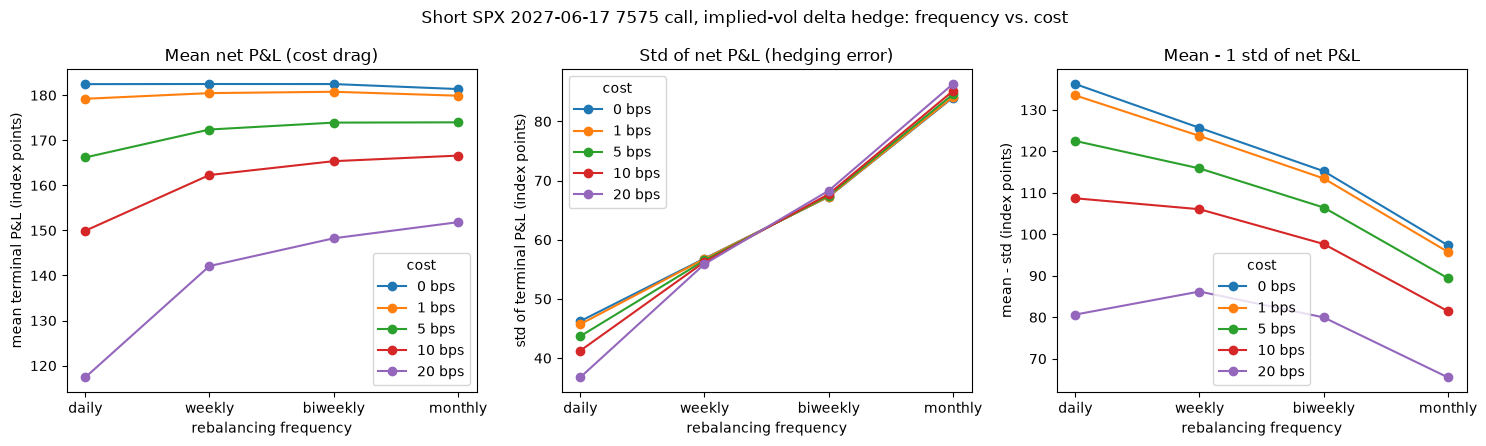

In [20]:
x = np.arange(len(FREQS))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for c in COSTS:
    axes[0].plot(x, net_table[(c, "mean")], "o-", label=f"{c} bps")
    axes[1].plot(x, net_table[(c, "std")], "o-", label=f"{c} bps")
    axes[2].plot(x, score_table[c], "o-", label=f"{c} bps")
titles = ["Mean net P&L (cost drag)", "Std of net P&L (hedging error)", "Mean - 1 std of net P&L"]
ylabels = ["mean terminal P&L (index points)", "std of terminal P&L (index points)", "mean - std (index points)"]
for ax, t, yl in zip(axes, titles, ylabels):
    ax.set_xticks(x, list(FREQS))
    ax.set_xlabel("rebalancing frequency")
    ax.set_ylabel(yl)
    ax.set_title(t)
    ax.legend(title="cost")
plt.suptitle(f"Short SPX {FAR_EXP.date()} {FAR_K:.0f} call, implied-vol delta hedge: frequency vs. cost")
plt.tight_layout()
plt.show()

Costs mostly eat into the mean, more so the more often you trade. They leave the weekly, biweekly and monthly std nearly unchanged and actually lower the daily std (46.24 to 36.74 at 20 bps). Daily rebalancing gives up 3.25 points of mean P&L at 1 bp, 16.27 at 5 bps and 65.07 at 20 bps, while monthly gives up only 29.54 even at 20 bps. The std nearly doubles from daily (43.69 at 5 bps) to monthly (84.57). For the sweet spot I used mean minus one standard deviation rather than mean over std, because the gross mean is mostly the volatility premium, which doesn't depend on hedge frequency. Mean minus one std puts cost drag and hedging error in the same index-point units. On that measure daily is best at 0, 1, 5 and 10 bps (122.50 vs. 115.88 for weekly at 5 bps, and only 108.68 vs. 106.04 at 10 bps) but weekly wins at 20 bps (86.20 vs. 80.65), so the sweet spot moves toward less frequent hedging as costs rise. Daily is the finest frequency in the grid, so at low costs the best choice may be daily or finer. On the real 4.2 path the daily hedge went from 74.79 with no costs to 60.84 at 5 bps and 18.99 at 20 bps.

## Section 6 — Model Limitations: What a Single $\sigma$ Misses

The strike is the November 20 put closest to 95% of spot, an out-of-the-money put where the smile is steep.

In [21]:
nov_iv = smile_chain[smile_chain["expiration"] == TODAY_NEAR_EXP]
nov_puts = nov_iv[(nov_iv["type"] == "put") & (nov_iv["status"] == "ok")].set_index("strike")
K6 = nov_puts.index[np.abs(nov_puts.index - 0.95 * S0).argmin()]
p6 = nov_puts.loc[K6]
atm_iv_nov = atm[TODAY_NEAR_EXP][0]

price_atm_vol = black_scholes(S0, K6, r0, atm_iv_nov, tau_near, "put")
price_own_vol = black_scholes(S0, K6, r0, p6["iv"], tau_near, "put")
print(f"strike: {K6:.0f} put (K/S = {K6 / S0:.3f}), expiry {TODAY_NEAR_EXP.date()}")
print(f"market bid / ask / mid: {p6['bid']:.2f} / {p6['ask']:.2f} / {p6['mid']:.2f}")
print(f"ATM IV: {atm_iv_nov:.4%}   strike's own IV: {p6['iv']:.4%}")
print(f"(a) price at ATM IV: {price_atm_vol:.2f}")
print(f"(b) price at own IV: {price_own_vol:.2f}")
print(f"difference (a) - (b): {price_atm_vol - price_own_vol:.2f}  ({(price_atm_vol - price_own_vol) / price_own_vol:.1%} of the own-IV price)")

strike: 7200 put (K/S = 0.950), expiry 2026-11-20
market bid / ask / mid: 32.90 / 33.70 / 33.30
ATM IV: 16.2292%   strike's own IV: 22.4513%
(a) price at ATM IV: 11.03
(b) price at own IV: 33.30
difference (a) - (b): -22.27  (-66.9% of the own-IV price)


The 7200 put's own implied vol is 22.45%, against 16.23% ATM for November. At the ATM vol it prices at 11.03 instead of 33.30, which is 22.27 points (\$2,227 per contract) lower, or 66.9% below its own-smile price (the mid, by construction). Using one vol for the whole expiration values this put at about a third of what the market charges. Selling it at that value would mean selling 21.87 below the 32.90 bid, roughly \$2,190 per SPX contract.

Black-Scholes assumes GBM with one constant $\sigma$, so log returns are normal, with thin tails and no skew. Real index returns have a fat left tail: big drops happen more often than a normal allows, and volatility rises when the market falls. A constant-$\sigma$ model can't price that strike-dependent crash risk, so matching the market takes a different $\sigma$ at each strike, which is the smile from Module 11, Part 4.

One alternative is stochastic volatility, such as Heston, where variance follows its own mean-reverting random process that is negatively correlated with the index. Volatility then tends to rise when prices fall, which fattens the left tail and produces the skew.

## Section 7 — Full Report: Pricing, Hedging, and a Trade Recommendation

In [22]:
CHOSEN_COST = 5                                   # bps; conservative for SPY (one-cent quoted spread is ~0.13 bps)
CHOSEN_FREQ = score_table[CHOSEN_COST].idxmax()   # best mean - 1 std at that cost (Section 5)
chosen = net[(CHOSEN_COST, CHOSEN_FREQ)]
far_atm_iv = atm[FAR_EXP][0]
far_own_vs_atm = black_scholes(S0, FAR_K, r0, far_atm_iv, far_tau) - black_scholes(S0, FAR_K, r0, far_iv, far_tau)
near_net_sim = near_sim(iv_d0, cost_bps=CHOSEN_COST)
real_net = real_hedge_pnl(near_path, NEAR_K, iv_d0, cost_bps=CHOSEN_COST)[0]

report = pd.Series({
    "Contract": f"SPX {FAR_K:.0f} call, expiring {FAR_EXP.date()} (European, AM-settled)",
    "Market mid price": f"{far_mid:.2f} (bid {far_q['bid']:.2f} / ask {far_q['ask']:.2f})",
    "Black-Scholes price (realized-vol sigma)": f"{black_scholes(S0, FAR_K, r0, sigma_rv, far_tau):.2f} at sigma = {sigma_rv:.2%}",
    "Black-Scholes price (implied sigma)": f"{black_scholes(S0, FAR_K, r0, far_iv, far_tau):.2f} at sigma = {far_iv:.2%}",
    "ATM implied vol vs. trailing realized vol": f"{far_atm_iv:.2%} vs. {sigma_rv:.2%} (63-day)",
    "Chosen rebalancing frequency and cost level": f"{CHOSEN_FREQ}, {CHOSEN_COST} bps",
    "Net-of-cost hedging P&L (4.1 sim): mean, std": f"{chosen.mean():.2f}, {chosen.std():.2f} (implied-vol hedge)",
    "4.2 real-path P&L and percentile": (f"{real_pnl['implied']:.2f} gross / {real_net:.2f} net (implied-vol hedge); "
                                         f"{pct(near_sim_pnl['implied'], real_pnl['implied']):.0f}th percentile of the matching near-contract sim, "
                                         f"{pct(far_pnl[('implied', 'daily')], real_pnl['implied']):.0f}th of the 4.1 far-contract daily sim"),
    "Mispricing from ATM vol instead of own smile vol": (f"{far_own_vs_atm:+.2f} on this near-ATM strike; "
                                                         f"{price_atm_vol - price_own_vol:+.2f} ({(price_atm_vol - price_own_vol) / price_own_vol:+.1%}) "
                                                         f"on the Section 6 {K6:.0f} put"),
}, name="Value")
report.index.name = "Item"
pd.set_option("display.max_colwidth", None)
report.to_frame()

,Value
Item,
Contract,"SPX 7575 call, expiring 2027-06-17 (European, AM-settled)"
Market mid price,506.60 (bid 505.20 / ask 508.00)
Black-Scholes price (realized-vol sigma),355.43 at sigma = 10.54%
Black-Scholes price (implied sigma),506.60 at sigma = 17.11%
ATM implied vol vs. trailing realized vol,17.30% vs. 10.54% (63-day)
Chosen rebalancing frequency and cost level,"daily, 5 bps"
"Net-of-cost hedging P&L (4.1 sim): mean, std","166.19, 43.69 (implied-vol hedge)"
4.2 real-path P&L and percentile,"74.79 gross / 60.84 net (implied-vol hedge); 99th percentile of the matching near-contract sim, 0th of the 4.1 far-contract daily sim"
Mispricing from ATM vol instead of own smile vol,+4.56 on this near-ATM strike; -22.27 (-66.9%) on the Section 6 7200 put


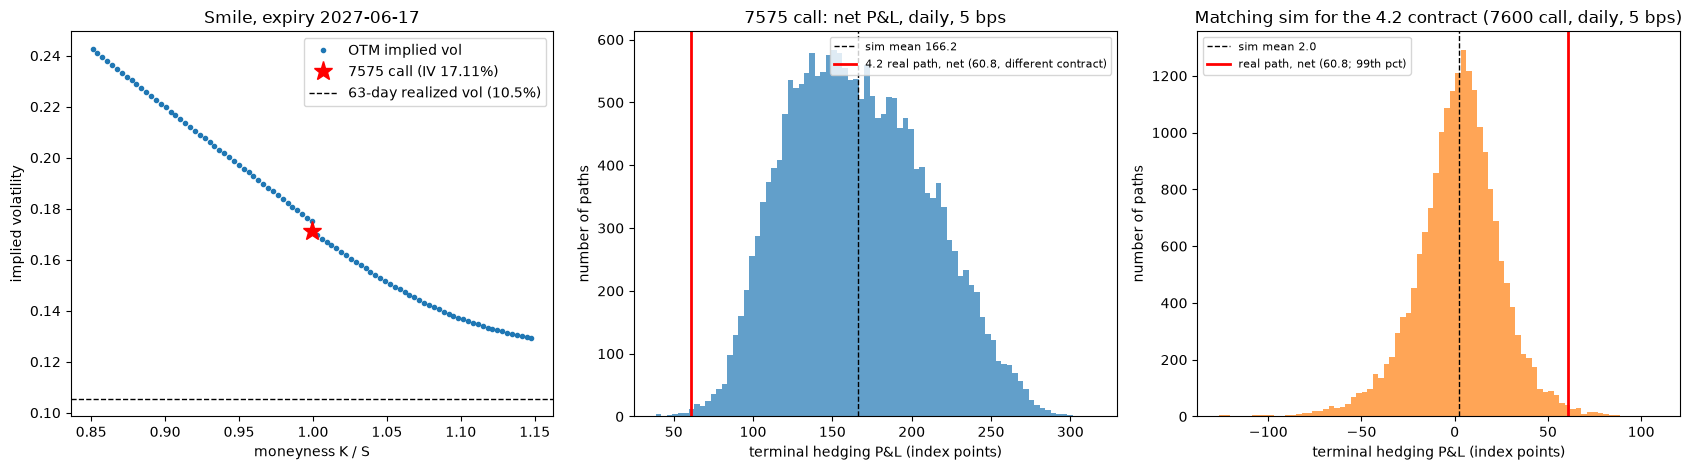

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
s = smile[smile["expiration"] == FAR_EXP]
axes[0].plot(s["moneyness"], s["iv"], "o", ms=3, label="OTM implied vol")
axes[0].plot(FAR_K / S0, far_iv, "r*", ms=14, label=f"{FAR_K:.0f} call (IV {far_iv:.2%})")
axes[0].axhline(sigma_rv, color="black", ls="--", lw=1, label=f"63-day realized vol ({sigma_rv:.1%})")
axes[0].set_title(f"Smile, expiry {FAR_EXP.date()}")
axes[0].set_xlabel("moneyness K / S"); axes[0].set_ylabel("implied volatility"); axes[0].legend()

axes[1].hist(chosen, bins=80, color="C0", alpha=0.7)
axes[1].axvline(chosen.mean(), color="black", ls="--", lw=1, label=f"sim mean {chosen.mean():.1f}")
axes[1].axvline(real_net, color="red", lw=2, label=f"4.2 real path, net ({real_net:.1f}, different contract)")
axes[1].set_title(f"{FAR_K:.0f} call: net P&L, {CHOSEN_FREQ}, {CHOSEN_COST} bps")
axes[1].set_xlabel("terminal hedging P&L (index points)"); axes[1].set_ylabel("number of paths"); axes[1].legend(loc="upper right", fontsize=8)

axes[2].hist(near_net_sim, bins=80, color="C1", alpha=0.7)
axes[2].axvline(near_net_sim.mean(), color="black", ls="--", lw=1, label=f"sim mean {near_net_sim.mean():.1f}")
axes[2].axvline(real_net, color="red", lw=2, label=f"real path, net ({real_net:.1f}; {pct(near_net_sim, real_net):.0f}th pct)")
axes[2].set_title(f"Matching sim for the 4.2 contract ({NEAR_K:.0f} call, daily, {CHOSEN_COST} bps)")
axes[2].set_xlabel("terminal hedging P&L (index points)"); axes[2].set_ylabel("number of paths"); axes[2].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

#### Desk Recommendation

At daily rebalancing and 5 bps, a Black-Scholes delta hedge handles the directional risk on this short June 2027 7575 call reasonably well: simulated net P&L averages 166.19 with a std of 43.69, and costs take only about 16 points. But the profit comes almost entirely from selling volatility at 17.11% while assuming SPX realizes 10.54% for 7.5 months, so it is really a short-volatility trade. The biggest unmanaged risk is Vega: at 23.25 points per vol point, a 10-point jump in implied vol would cost roughly 230 points mark-to-market, more than the expected profit, and even a 5-point rise would cost about 116. Before trading this at size I'd want a Vega hedge with a second option and a stress test for a gap down with a vol spike.

### Interpretation

Put-call parity held once spreads and dividends were accounted for. The textbook formula showed a 3.83-point profit after crossing both spreads, but it came from the 4.38-point dividend term the formula leaves out. With dividends included the best trade lost 0.55 points and no strike was profitable, so I found no genuine violation.

At the 5 bps I assumed, transaction costs mattered more to final P&L than the hedging $\sigma$. In the simulation, switching from realized to implied $\sigma$ moved the daily mean by 5.86 points (188.32 vs. 182.46), while 5 bps of costs took 16.27 and 20 bps took 65.07. On the real path the $\sigma$ choice changed P&L by 0.54 and 5 bps of costs took 13.95. That surprised me a little, since Section 4 makes the $\sigma$ choice look like the main decision, but it mostly changes the spread of outcomes (std 20.57 vs. 46.24), not the average. The ranking depends on the cost level, though. At 1 bp costs take only 3.25, less than the 5.86 from the $\sigma$ choice, and SPY's one-cent spread is about 0.13 bps, so at realistic SPY costs the $\sigma$ choice matters more even for the mean.

The first thing I'd change is adding a Vega hedge with a second option. In my Section 7 table daily rebalancing is already the sweet spot, costs take only about 16 of the 182 points of expected P&L, and a strike-specific vol adds just 4.56 points since 7575 is at the money. The real exposure is volatility: the 166.19 expected net P&L depends on the 6.6-point gap between the 17.11% the call was sold at and the 10.54% the simulation assumes SPX realizes. A Vega hedge would give back part of that premium, since the second option is bought at a similar implied vol, but it caps the 23.25-point-per-vol-point mark-to-market risk.

## Section 8 — Bonus: Implied-Volatility Term Structure

I chose the term structure because it uses only the real chain with no new modeling assumptions, and it asks whether one volatility is appropriate across maturities as well as strikes. Today's file is reprocessed with the Section 1.4 `process_day` for every listed expiration within ±3% of spot, and cached. ATM implied vol is computed as in Section 3, with today's 3-month T-bill rate at every maturity.

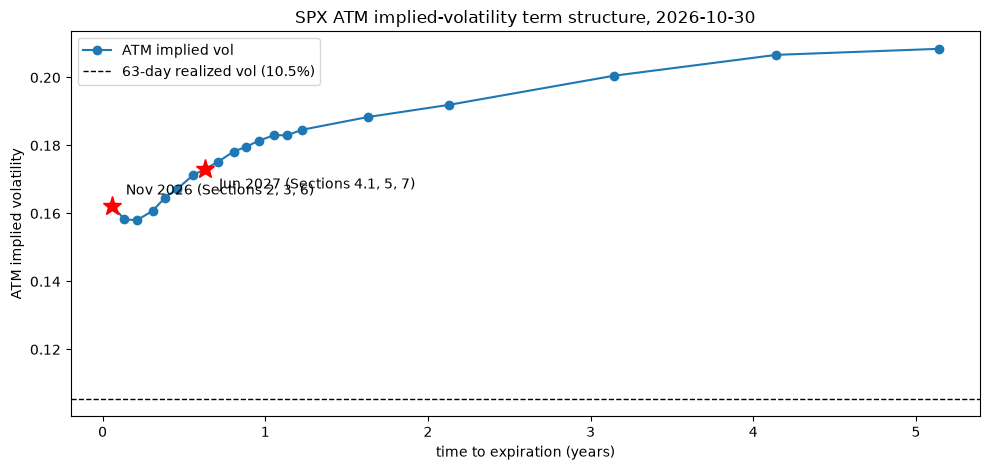

,tau (yr),ATM strike,ATM IV
expiration,,,
2026-11-20,0.0575,7580.0,0.1623
2026-12-18,0.1342,7580.0,0.1583
2027-01-15,0.2110,7580.0,0.1580
2027-02-19,0.3068,7580.0,0.1607
2027-03-19,0.3836,7575.0,0.1646
2027-04-16,0.4603,7575.0,0.1673
2027-05-21,0.5562,7575.0,0.1713
2027-06-17,0.6301,7575.0,0.1730
2027-07-16,0.7096,7575.0,0.1752


In [24]:
ts_cache = CACHE_DIR / f"term_structure_{TODAY:%Y%m%d}.pkl"
if ts_cache.exists():
    ts_chain = pd.read_pickle(ts_cache)
else:
    all_codes = {e.strftime("%y%m%d") for e in exp_last}
    ts_chain = process_day(raw_files[-1], TODAY, S0, exp_codes=all_codes, band=0.03)
    ts_chain.to_pickle(ts_cache)

ts_rows = []
for e, g in ts_chain.groupby("expiration"):
    g = g.copy()
    g["iv"] = [iv_or_reason(q.mid, q.bid, q.ask, S0, q.strike, r0, q.tau, q.type)[0] for q in g.itertuples()]
    iv, k = atm_iv(g, S0)
    ts_rows.append({"expiration": e.date(), "tau (yr)": g["tau"].iloc[0], "ATM strike": k, "ATM IV": iv})
term = pd.DataFrame(ts_rows).set_index("expiration")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(term["tau (yr)"], term["ATM IV"], "o-", label="ATM implied vol")
for e, lab, off in [(TODAY_NEAR_EXP, "Nov 2026 (Sections 2, 3, 6)", (10, 8)), (FAR_EXP, "Jun 2027 (Sections 4.1, 5, 7)", (10, -14))]:
    ax.plot(term.loc[e.date(), "tau (yr)"], term.loc[e.date(), "ATM IV"], "r*", ms=14)
    ax.annotate(lab, (term.loc[e.date(), "tau (yr)"], term.loc[e.date(), "ATM IV"]), textcoords="offset points", xytext=off)
ax.axhline(sigma_rv, color="black", ls="--", lw=1, label=f"63-day realized vol ({sigma_rv:.1%})")
ax.set_xlabel("time to expiration (years)")
ax.set_ylabel("ATM implied volatility")
ax.set_title(f"SPX ATM implied-volatility term structure, {TODAY.date()}")
ax.legend()
plt.tight_layout()
plt.show()
term.round(4)

The term structure slopes upward. ATM implied vol dips from 16.23% in November to about 15.8% in December and January, then rises to 17.30% for June 2027, 18.3% at one year and 20.8% at five years, all far above the 10.54% realized vol. The bump at the front is probably the November 3 election: its variance is spread over 21 days for November but 49 for December, so it raises November's annualized vol more. The upward slope is normal after a calm stretch, since volatility mean-reverts toward its long-run level.

This changes how I read Section 7. The 4.1 simulation assumed SPX realizes 10.54% for all 7.5 months, but the market expects volatility to rise. So much of the 151-point gap between the mid and the realized-vol price is probably expected mean reversion rather than pure risk premium, which makes the simulated 166.19 net profit look optimistic and is another reason for the Vega hedge.